<a href="https://colab.research.google.com/github/delowar-miah/Data-store-and-Retrive-from-RealTime-FirebaseDatabase/blob/master/Data_cleaning_preprocession.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
pd.set_option('display.max_columns', 50)
DATA_PATH=Path("/uk_workplace_data_cleaning_messy_dataset.csv")

In [46]:
df_raw=pd.read_csv(DATA_PATH)
df=df_raw.copy()
df.shape

(620, 14)

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 620 entries, 0 to 619
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   learner_id                620 non-null    object 
 1   department                602 non-null    object 
 2   region                    596 non-null    object 
 3   role_family               620 non-null    object 
 4   employee_band             620 non-null    object 
 5   training_type             620 non-null    object 
 6   enrolment_date            620 non-null    object 
 7   prior_python_score        585 non-null    float64
 8   course_minutes            620 non-null    float64
 9   engagement_score          590 non-null    float64
 10  manager_support_score     606 non-null    float64
 11  support_tickets_last_30d  620 non-null    object 
 12  completion_days           602 non-null    float64
 13  completed_on_time         620 non-null    int64  
dtypes: float64

In [48]:
df.head()

,learner_id,department,region,role_family,employee_band,training_type,enrolment_date,prior_python_score,course_minutes,engagement_score,manager_support_score,support_tickets_last_30d,completion_days,completed_on_time
0,L10387,OPERATIONS,Remote,Technician,A,ML Foundations,2026-02-15,41.9,189.8,91.3,4.0,1,20.0,1
1,L10089,Sales,Unknown,Associate,A,ML Foundations,2026-02-07,39.6,191.8,84.7,NaN,1,23.0,1
2,L10448,operations,Manchester,Analyst,B,AI Awareness,2026-03-10,36.1,93.6,100.0,1.0,3,13.0,1
3,L10599,Human Resources,Manchester,Technician,C,AI Awareness,2026-01-05,55.7,186.0,37.1,4.0,4,8.0,0
4,L10227,IT,Edinburgh,Coordinator,B,Data Literacy,2026-03-08,10.6,237.5,47.9,1.0,1,15.0,0


In [51]:
def diagnostic_summary(dataframe):
  summary=pd.DataFrame({
      'dtype':dataframe.dtypes.astype(str),
      'missing_count':dataframe.isna().sum(),
       'missing_pct':(dataframe.isna().mean() * 100).round(2),
      'unique-values':dataframe.nunique(dropna=True)
  })
  return summary.sort_values('missing_pct',ascending=False)
  before_summary=diagnostic_summary(df)
  before_summary


In [52]:

def diagnostic_summary(dataframe):
    summary = pd.DataFrame({
        'dtype': dataframe.dtypes.astype(str),
        'missing_count': dataframe.isna().sum(),
        'missing_pct': (dataframe.isna().mean() * 100).round(2),
        'unique_values': dataframe.nunique(dropna=True)
    })
    return summary.sort_values('missing_pct', ascending=False)

before_summary = diagnostic_summary(df)
before_summary


,dtype,missing_count,missing_pct,unique_values
prior_python_score,float64,35,5.65,373
engagement_score,float64,30,4.84,367
region,object,24,3.87,11
completion_days,float64,18,2.90,32
department,object,18,2.90,13
manager_support_score,float64,14,2.26,5
training_type,object,0,0.00,5
employee_band,object,0,0.00,4
role_family,object,0,0.00,6
learner_id,object,0,0.00,600


In [55]:
exact_duplicated=df.duplicated().sum()
print('Show duplicate rows:',exact_duplicated)

Show duplicate rows: 20


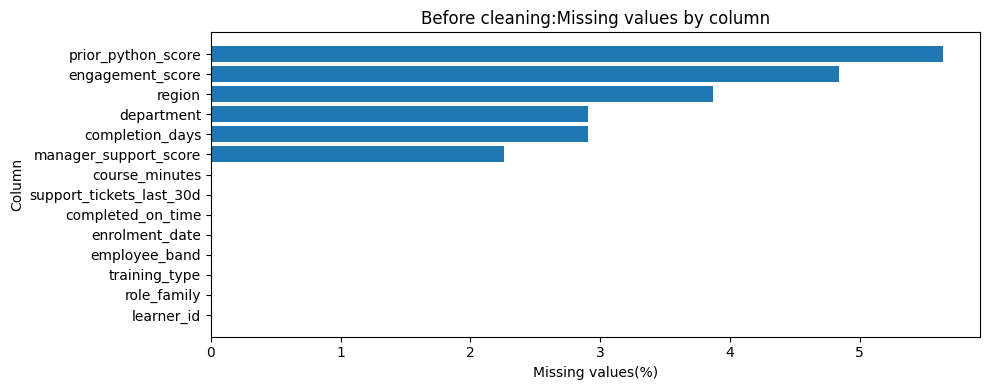

In [57]:
plt.figure(figsize=(10,4))
missing_pct=(df.isna().mean() * 100).sort_values(ascending=True)
plt.barh(missing_pct.index.astype(str),missing_pct.values)
plt.title('Before cleaning:Missing values by column')
plt.xlable("Missing values(%)")
plt.ylable('Column')
plt.tight_layout()
plt.show()

In [60]:
df['supoort_tickets_last_30d'] = (
    df['support_tickets_last_30d']
    .astype(str)
    .str.extract(r'(\d+)')[0]
    .astype(float)
)

In [62]:
def clean_text_category(series):
    return(
        series.astype('string')
        .str.strip()
        .str.lower()
        .replace({
            '<na>':pd.NA,
            'nan':pd.NA,
            'none':pd.NA,
            '':pd.NA
        })
    )

In [ ]:
## Map known category synonames

In [69]:
membership ={
    'Human Resources': 'hr',
    'Information Technology': 'it',
    'support': 'customer support',
    'OPERATIONS': 'operations',
    'finance': 'finance',
    'Sales': 'sales'
}
df['department']=df['department'].replace(membership)
df['region']=df['region'].replace({
    'remote':'remote',
    'Unknown':pd.NA
})
df[['department','region','training_type']].head()


,department,region,training_type
0,OPERATIONS,Remote,ML Foundations
1,sales,<NA>,ML Foundations
2,operations,Manchester,AI Awareness
3,hr,Manchester,AI Awareness
4,IT,Edinburgh,Data Literacy


**Parse dates and flag invalid values.In a production workflow, invalid dates should be investigated. In this training dataset, we convert invalid dates to missing values and create a flag.**

In [71]:

df['enrolment_date_parsed'] = pd.to_datetime(
    df['enrolment_date'],
    errors='coerce',
    dayfirst=False
)

df['enrolment_date_invalid_flag'] = (
    df['enrolment_date_parsed'].isna().astype(int)
)

df[['enrolment_date',
    'enrolment_date_parsed',
    'enrolment_date_invalid_flag']].head(10)


,enrolment_date,enrolment_date_parsed,enrolment_date_invalid_flag
0,2026-02-15,2026-02-15,0
1,2026-02-07,2026-02-07,0
2,2026-03-10,2026-03-10,0
3,2026-01-05,2026-01-05,0
4,2026-03-08,2026-03-08,0
5,2026-01-28,2026-01-28,0
6,2026-03-28,2026-03-28,0
7,2026-03-01,2026-03-01,0
8,07/01/2026,NaT,1
9,2026-03-31,2026-03-31,0


 ## **Cleaning should preserve signal. Instead of deleting rows immediately, first convert impossible values to missing and create flags**

In [73]:
# First, fix the typo from the previous step by overwriting the correct column with numeric values
df['support_tickets_last_30d'] = (
    df['support_tickets_last_30d']
    .astype(str)
    .str.extract(r'(\d+)')[0]
    .astype(float)
)

range_rules = {
    'prior_python_score': (0, 100),
    'engagement_score': (0, 100),
    'course_minutes': (0, 480),
    'manager_support_score': (1, 5),
    'support_tickets_last_30d': (0, 50),
    'completion_days': (0, 120)
}

for col, (low, high) in range_rules.items():
    invalid = ~df[col].between(low, high) & df[col].notna()
    df[f'{col}_invalid_flag'] = invalid.astype(int)
    df.loc[invalid, col] = np.nan

invalid_flag_cols = [c for c in df.columns if c.endswith('_invalid_flag')]
df[invalid_flag_cols].sum().sort_values(ascending=False)

,0
enrolment_date_invalid_flag,11
prior_python_score_invalid_flag,0
engagement_score_invalid_flag,0
course_minutes_invalid_flag,0
manager_support_score_invalid_flag,0
support_tickets_last_30d_invalid_flag,0
completion_days_invalid_flag,0


Handle missing values with explicit decisions

For this short activity:
- numerical columns use median imputation;
- categorical columns use `unknown`;
- flags preserve the fact that values were missing or invalid.

In a real modelling pipeline, imputation should be fitted on the training set only.

In [76]:

numeric_cols = [
    'prior_python_score',
    'course_minutes',
    'engagement_score',
    'manager_support_score',
    'support_tickets_last_30d',
    'completion_days'
]

categorical_cols = [
    'department',
    'region',
    'role_family',
    'employee_band',
    'training_type'
]

for col in numeric_cols:
    df[f'{col}_missing_flag'] = df[col].isna().astype(int)
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[f'{col}_missing_flag'] = df[col].isna().astype(int)
    df[col] = df[col].fillna('unknown')


In [77]:
df.head(20)

,learner_id,department,region,role_family,employee_band,training_type,enrolment_date,prior_python_score,course_minutes,engagement_score,manager_support_score,support_tickets_last_30d,completion_days,completed_on_time,supoort_tickets_last_30d,enrolment_date_parsed,enrolment_date_invalid_flag,prior_python_score_invalid_flag,engagement_score_invalid_flag,course_minutes_invalid_flag,manager_support_score_invalid_flag,support_tickets_last_30d_invalid_flag,completion_days_invalid_flag,prior_python_score_missing_flag,course_minutes_missing_flag,engagement_score_missing_flag,manager_support_score_missing_flag,support_tickets_last_30d_missing_flag,completion_days_missing_flag,department_missing_flag,region_missing_flag,role_family_missing_flag,employee_band_missing_flag,training_type_missing_flag
0,L10387,OPERATIONS,Remote,Technician,A,ML Foundations,2026-02-15,41.9,189.8,91.3,4.0,1.0,20.0,1,1.0,2026-02-15,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,L10089,sales,unknown,Associate,A,ML Foundations,2026-02-07,39.6,191.8,84.7,3.0,1.0,23.0,1,1.0,2026-02-07,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,L10448,operations,Manchester,Analyst,B,AI Awareness,2026-03-10,36.1,93.6,100.0,1.0,3.0,13.0,1,3.0,2026-03-10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,L10599,hr,Manchester,Technician,C,AI Awareness,2026-01-05,55.7,186.0,37.1,4.0,4.0,8.0,0,4.0,2026-01-05,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,L10227,IT,Edinburgh,Coordinator,B,Data Literacy,2026-03-08,10.6,237.5,47.9,1.0,1.0,15.0,0,1.0,2026-03-08,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,L10139,Operations,London,Analyst,A,Data Literacy,2026-01-28,51.6,243.0,77.7,2.0,4.0,19.0,1,4.0,2026-01-28,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,L10522,finance,Remote,Specialist,C,Responsible AI,2026-03-28,38.4,176.1,66.5,3.0,0.0,12.0,1,0.0,2026-03-28,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,L10284,sales,London,Manager,B,AI Awareness,2026-03-01,53.4,177.4,87.8,2.0,2.0,10.0,0,2.0,2026-03-01,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,L10124,it,Birmingham,Analyst,A,AI Awareness,07/01/2026,43.9,125.6,35.0,3.0,2.0,24.0,0,2.0,NaT,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,L10054,sales,Edinburgh,Analyst,A,Python Basics,2026-03-31,53.4,98.8,53.0,1.0,1.0,14.0,0,1.0,2026-03-31,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Remove exact duplicate rows

Exact duplicates can overweight a record. We remove exact duplicate rows after standardising obvious formats.

In [78]:
rows_before = len(df)
df=df.drop_duplicates(ignore_index=True)
rows_after=len(df)
print('Rows before:',rows_before)
print('Rows after:',rows_after)
print('Removed rows:',rows_before - rows_after)

Rows before: 620
Rows after: 600
Removed rows: 20


In [81]:
df.head(20)

,learner_id,department,region,role_family,employee_band,training_type,enrolment_date,prior_python_score,course_minutes,engagement_score,manager_support_score,support_tickets_last_30d,completion_days,completed_on_time,supoort_tickets_last_30d,enrolment_date_parsed,enrolment_date_invalid_flag,prior_python_score_invalid_flag,engagement_score_invalid_flag,course_minutes_invalid_flag,manager_support_score_invalid_flag,support_tickets_last_30d_invalid_flag,completion_days_invalid_flag,prior_python_score_missing_flag,course_minutes_missing_flag,engagement_score_missing_flag,manager_support_score_missing_flag,support_tickets_last_30d_missing_flag,completion_days_missing_flag,department_missing_flag,region_missing_flag,role_family_missing_flag,employee_band_missing_flag,training_type_missing_flag
0,L10387,OPERATIONS,Remote,Technician,A,ML Foundations,2026-02-15,41.9,189.8,91.3,4.0,1.0,20.0,1,1.0,2026-02-15,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,L10089,sales,unknown,Associate,A,ML Foundations,2026-02-07,39.6,191.8,84.7,3.0,1.0,23.0,1,1.0,2026-02-07,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,L10448,operations,Manchester,Analyst,B,AI Awareness,2026-03-10,36.1,93.6,100.0,1.0,3.0,13.0,1,3.0,2026-03-10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,L10599,hr,Manchester,Technician,C,AI Awareness,2026-01-05,55.7,186.0,37.1,4.0,4.0,8.0,0,4.0,2026-01-05,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,L10227,IT,Edinburgh,Coordinator,B,Data Literacy,2026-03-08,10.6,237.5,47.9,1.0,1.0,15.0,0,1.0,2026-03-08,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,L10139,Operations,London,Analyst,A,Data Literacy,2026-01-28,51.6,243.0,77.7,2.0,4.0,19.0,1,4.0,2026-01-28,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,L10522,finance,Remote,Specialist,C,Responsible AI,2026-03-28,38.4,176.1,66.5,3.0,0.0,12.0,1,0.0,2026-03-28,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,L10284,sales,London,Manager,B,AI Awareness,2026-03-01,53.4,177.4,87.8,2.0,2.0,10.0,0,2.0,2026-03-01,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,L10124,it,Birmingham,Analyst,A,AI Awareness,07/01/2026,43.9,125.6,35.0,3.0,2.0,24.0,0,2.0,NaT,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,L10054,sales,Edinburgh,Analyst,A,Python Basics,2026-03-31,53.4,98.8,53.0,1.0,1.0,14.0,0,1.0,2026-03-31,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Review outliers using a boxplot

A boxplot helps reveal extreme values. Outliers are not automatically wrong; they need judgement.

/tmp/ipykernel_11890/3335485901.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


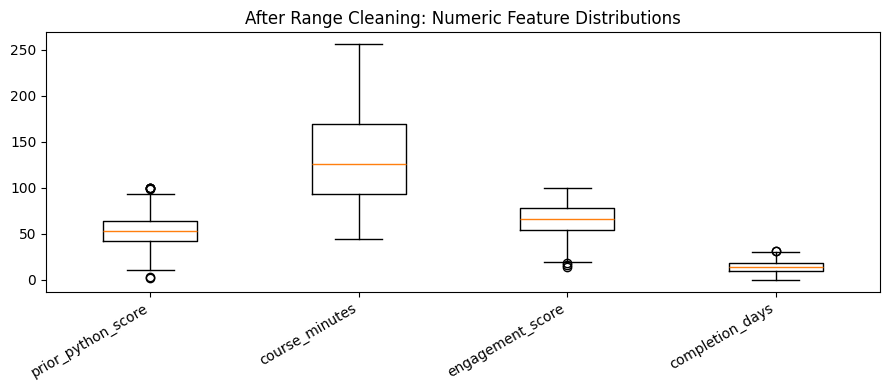

In [82]:

plt.figure(figsize=(9, 4))

plot_cols = [
    'prior_python_score',
    'course_minutes',
    'engagement_score',
    'completion_days'
]

plt.boxplot(
    [df[col].dropna() for col in plot_cols],
    labels=plot_cols
)

plt.title('After Range Cleaning: Numeric Feature Distributions')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


Scale numerical variables and encode categories

For this session we use Pandas/NumPy only. Later modelling sessions will use formal preprocessing pipelines.

In [84]:

for col in [
    'prior_python_score',
    'course_minutes',
    'engagement_score',
    'support_tickets_last_30d'
]:
    std = df[col].std(ddof=0)

    df[f'{col}_zscore'] = (
        0 if std == 0
        else (df[col] - df[col].mean()) / std
    )


/tmp/ipykernel_11890/1696379660.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[f'{col}_zscore'] = (


One-hot encode selected categorical variables

In [85]:
encoded = pd.get_dummies(df[['department', 'region', 'training_type']], prefix=['dept', 'region', 'training'], dtype=int)
model_ready = pd.concat([df, encoded], axis=1)
model_ready.head()

,learner_id,department,region,role_family,employee_band,training_type,enrolment_date,prior_python_score,course_minutes,engagement_score,manager_support_score,support_tickets_last_30d,completion_days,completed_on_time,supoort_tickets_last_30d,enrolment_date_parsed,enrolment_date_invalid_flag,prior_python_score_invalid_flag,engagement_score_invalid_flag,course_minutes_invalid_flag,manager_support_score_invalid_flag,support_tickets_last_30d_invalid_flag,completion_days_invalid_flag,prior_python_score_missing_flag,course_minutes_missing_flag,...,dept_IT,dept_Operations,dept_Support,dept_finance,dept_hr,dept_it,dept_operations,dept_sales,dept_unknown,region_Birmingham,region_Bristol,region_Cardiff,region_Edinburgh,region_Leeds,region_London,region_Manchester,region_REMOTE,region_Remote,region_remote,region_unknown,training_AI Awareness,training_Data Literacy,training_ML Foundations,training_Python Basics,training_Responsible AI
0,L10387,OPERATIONS,Remote,Technician,A,ML Foundations,2026-02-15,41.9,189.8,91.3,4.0,1.0,20.0,1,1.0,2026-02-15,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0
1,L10089,sales,unknown,Associate,A,ML Foundations,2026-02-07,39.6,191.8,84.7,3.0,1.0,23.0,1,1.0,2026-02-07,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0
2,L10448,operations,Manchester,Analyst,B,AI Awareness,2026-03-10,36.1,93.6,100.0,1.0,3.0,13.0,1,3.0,2026-03-10,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0
3,L10599,hr,Manchester,Technician,C,AI Awareness,2026-01-05,55.7,186.0,37.1,4.0,4.0,8.0,0,4.0,2026-01-05,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0
4,L10227,IT,Edinburgh,Coordinator,B,Data Literacy,2026-03-08,10.6,237.5,47.9,1.0,1.0,15.0,0,1.0,2026-03-08,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0


After-cleaning diagnostics

Compare before and after. A good cleaning notebook proves the impact of every major decision.

In [87]:
after_summary = diagnostic_summary(model_ready)
comparison = pd.DataFrame({
    'metric': ['rows', 'columns', 'missing_cells', 'exact_duplicates'],
    'before': [df_raw.shape[0], df_raw.shape[1], int(df_raw.isna().sum().sum()), int(df_raw.duplicated().sum())],
    'after': [model_ready.shape[0], model_ready.shape[1], int(model_ready.isna().sum().sum()), int(model_ready.duplicated().sum())]
})

Save CSV file

In [88]:
model_ready.to_csv('cleaned_session_03_dataset.csv', index=False)
comparison.to_csv('before_after_diagnostics.csv', index=False)
print('Saved cleaned_session_03_dataset.csv and before_after_diagnostics.csv')

Saved cleaned_session_03_dataset.csv and before_after_diagnostics.csv
